# Proyek Analisis Data: [Input Nama Dataset]
- **Nama:** Larry Polin Anugrah
- **Email:** larrypolin1710@gmail.com
- **ID Dicoding:** larry_polin_anugrah

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Berapa persen rata-rata PM2.5 di 12 stasiun Beijing pada musim pemanasan (November–Maret) lebih tinggi dibandingkan musim non-pemanasan (April–Oktober) selama Maret 2013–Februari 2017, dan perlukah pembatasan emisi difokuskan pada bulan-bulan tersebut?

- **Pertanyaan 2:** Stasiun mana yang memiliki persentase jam dengan PM2.5 di atas 115 µg/m³ paling tinggi dan paling rendah selama Maret 2013–Februari 2017, dan stasiun mana yang perlu diprioritaskan untuk pengawasan?

- **Pertanyaan 3:** Berapa persen rata-rata PM2.5 turun saat kecepatan angin di atas 5 m/s dibandingkan saat 1 m/s atau kurang di 12 stasiun Beijing selama Maret 2013–Februari 2017, dan pada kecepatan berapa peringatan polusi perlu diaktifkan?

## Import Semua Packages/Library yang Digunakan

In [28]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import folium

## Data Wrangling

### Gathering Data

#### Load df ...

In [29]:
files = sorted(glob.glob('PRSA_Data_*.csv'))
print(f'Jumlah file: {len(files)}')
df_raw = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
print('Ukuran data setelah penggabungan:', df_raw.shape)
df_raw.head()

Jumlah file: 12
Ukuran data setelah penggabungan: (420768, 18)


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,4.00,4.00,4.00,7.00,300.00,77.00,-0.70,"1,023.00",-18.80,0.00,NNW,4.40,Aotizhongxin
1,2,2013,3,1,1,8.00,8.00,4.00,7.00,300.00,77.00,-1.10,"1,023.20",-18.20,0.00,N,4.70,Aotizhongxin
2,3,2013,3,1,2,7.00,7.00,5.00,10.00,300.00,73.00,-1.10,"1,023.50",-18.20,0.00,NNW,5.60,Aotizhongxin
3,4,2013,3,1,3,6.00,6.00,11.00,11.00,300.00,72.00,-1.40,"1,024.50",-19.40,0.00,NW,3.10,Aotizhongxin
4,5,2013,3,1,4,3.00,3.00,12.00,12.00,300.00,72.00,-2.00,"1,025.20",-19.50,0.00,N,2.00,Aotizhongxin


**Insight:** (Opsional)
- Data hasil penggabungan berisi **420.768 baris × 18 kolom**, yang terdiri dari 12 stasiun berbeda
- Kolom waktu terpisah (`year`, `month`, `day`, `hour`) sehingga perlu digabung menjadi satu kolom `datetime` pada tahap cleaning.

### Assessing Data

#### Identifying Data Quality problem

##### Memeriksa tipe data

In [30]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420768 entries, 0 to 420767
Data columns (total 18 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   No       420768 non-null  int64  
 1   year     420768 non-null  int64  
 2   month    420768 non-null  int64  
 3   day      420768 non-null  int64  
 4   hour     420768 non-null  int64  
 5   PM2.5    412029 non-null  float64
 6   PM10     414319 non-null  float64
 7   SO2      411747 non-null  float64
 8   NO2      408652 non-null  float64
 9   CO       400067 non-null  float64
 10  O3       407491 non-null  float64
 11  TEMP     420370 non-null  float64
 12  PRES     420375 non-null  float64
 13  DEWP     420365 non-null  float64
 14  RAIN     420378 non-null  float64
 15  wd       418946 non-null  object 
 16  WSPM     420450 non-null  float64
 17  station  420768 non-null  object 
dtypes: float64(11), int64(5), object(2)
memory usage: 57.8+ MB


In [31]:
df_raw.describe()

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM
count,"420,768.00","420,768.00","420,768.00","420,768.00","420,768.00","412,029.00","414,319.00","411,747.00","408,652.00","400,067.00","407,491.00","420,370.00","420,375.00","420,365.00","420,378.00","420,450.00"
mean,"17,532.50","2,014.66",6.52,15.73,11.50,79.79,104.60,15.83,50.64,"1,230.77",57.37,13.54,"1,010.75",2.49,0.06,1.73
std,"10,122.12",1.18,3.45,8.80,6.92,80.82,91.77,21.65,35.13,"1,160.18",56.66,11.44,10.47,13.79,0.82,1.25
min,1.00,"2,013.00",1.00,1.00,0.00,2.00,2.00,0.29,1.03,100.00,0.21,-19.90,982.40,-43.40,0.00,0.00
25%,"8,766.75","2,014.00",4.00,8.00,5.75,20.00,36.00,3.00,23.00,500.00,11.00,3.10,"1,002.30",-8.90,0.00,0.90
50%,"17,532.50","2,015.00",7.00,16.00,11.50,55.00,82.00,7.00,43.00,900.00,45.00,14.50,"1,010.40",3.10,0.00,1.40
75%,"26,298.25","2,016.00",10.00,23.00,17.25,111.00,145.00,20.00,71.00,"1,500.00",82.00,23.30,"1,019.00",15.10,0.00,2.20
max,"35,064.00","2,017.00",12.00,31.00,23.00,999.00,999.00,500.00,290.00,"10,000.00","1,071.00",41.60,"1,042.80",29.10,72.50,13.20


**Insight:**
- Data berisi 420.768 baris dan 18 kolom (11 `float64`, 5 `int64`, 2 `object`) dengan penggunaan memori sekitar 57,8 MB.
- Kolom waktu (`year`, `month`, `day`, `hour`) masih terpisah dalam 4 kolom `int64` dan belum ada kolom bertipe `datetime`, sehingga perlu digabung menjadi satu kolom `datetime` agar analisis tren waktu lebih mudah.
- Kolom `No` hanya nomor urut baris per stasiun dan tidak berguna untuk analisis, sehingga bisa dihapus.
- Kolom `wd` dan `station` bertipe `object` (teks kategorik). Ini sudah sesuai, tetapi bisa diubah menjadi `category` bila ingin menghemat memori.
- Semua kolom polutan dan cuaca sudah bertipe numerik (`float64`), jadi tidak perlu konversi tipe.
- Kolom `No`, `year`, `month`, `day`, `hour`, dan `station` terisi penuh (420.768 data), sedangkan kolom polutan dan cuaca punya jumlah non-null lebih sedikit. Ini menunjukkan adanya missing value yang diperiksa pada langkah berikutnya. Kolom `CO` paling banyak kosongnya (400.067 non-null, atau sekitar 20.700 data kosong), disusul `O3`, `NO2`, dan `PM2.5`.

##### Memeriksa Missing Value

In [32]:
missing = pd.DataFrame({
    'jumlah_missing': df_raw.isna().sum(),
    'persen_missing': df_raw.isna().mean() * 100
}).query('jumlah_missing > 0').sort_values('jumlah_missing', ascending=False)
missing

,jumlah_missing,persen_missing
CO,20701,4.92
O3,13277,3.16
NO2,12116,2.88
SO2,9021,2.14
PM2.5,8739,2.08
PM10,6449,1.53
wd,1822,0.43
DEWP,403,0.10
TEMP,398,0.09
PRES,393,0.09


##### Memeriksa data duplikat dan kelengkapan rentang waktu

In [33]:
df_cek = df_raw.copy()
df_cek['datetime'] = pd.to_datetime(df_cek[['year', 'month', 'day', 'hour']])

print('Baris duplikat penuh                :', df_cek.duplicated().sum())
print('Duplikat kombinasi (station, waktu) :', df_cek.duplicated(['station', 'datetime']).sum())

expected = pd.date_range('2013-03-01 00:00', '2017-02-28 23:00', freq='h')
print('\nJumlah jam yang seharusnya per stasiun:', len(expected))
print(df_cek.groupby('station')['datetime'].nunique().to_frame('jam_tercatat').T)

Baris duplikat penuh                : 0
Duplikat kombinasi (station, waktu) : 0

Jumlah jam yang seharusnya per stasiun: 35064
station       Aotizhongxin  Changping  Dingling  Dongsi  Guanyuan  Gucheng  \
jam_tercatat         35064      35064     35064   35064     35064    35064   

station       Huairou  Nongzhanguan  Shunyi  Tiantan  Wanliu  Wanshouxigong  
jam_tercatat    35064         35064   35064    35064   35064          35064  


##### Memeriksa Inconsistent Value

In [34]:
invalid_pm = df_raw[df_raw['PM2.5'] > df_raw['PM10']]
print(f"Baris dengan PM2.5 > PM10: {len(invalid_pm):,} ({len(invalid_pm)/len(df_raw):.1%} dari seluruh baris)")

print('\nKategori arah angin (wd):')
print(df_raw['wd'].value_counts(dropna=False).to_dict())

print('\nNilai minimum tiap kolom numerik:')
print(df_raw[['PM2.5','PM10','SO2','NO2','CO','O3','TEMP','PRES','DEWP','RAIN','WSPM']].min())

Baris dengan PM2.5 > PM10: 21,312 (5.1% dari seluruh baris)

Kategori arah angin (wd):
{'NE': 43335, 'ENE': 34142, 'NW': 32600, 'N': 30869, 'E': 29752, 'SW': 28756, 'NNE': 28232, 'NNW': 25326, 'WNW': 24375, 'ESE': 24220, 'SSW': 22563, 'SE': 20074, 'WSW': 20040, 'S': 19405, 'SSE': 17694, 'W': 17563, nan: 1822}

Nilai minimum tiap kolom numerik:
PM2.5     2.00
PM10      2.00
SO2       0.29
NO2       1.03
CO      100.00
O3        0.21
TEMP    -19.90
PRES    982.40
DEWP    -43.40
RAIN      0.00
WSPM      0.00
dtype: float64


##### Memeriksa *outlier* pada PM2.5

Batas atas IQR: 247.5 µg/m³ | Jumlah outlier: 19,142 (4.6%)
Nilai maksimum PM2.5: 999.0


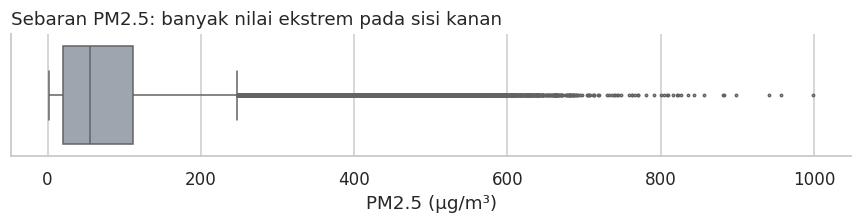

In [35]:
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110})

ACCENT = '#C0392B'
BASE   = '#9AA5B1'
DARK   = '#2C3E50'

q1, q3 = df_raw['PM2.5'].quantile([.25, .75])
iqr = q3 - q1
batas_atas = q3 + 1.5 * iqr
n_out = (df_raw['PM2.5'] > batas_atas).sum()
print(f'Batas atas IQR: {batas_atas:.1f} µg/m³ | Jumlah outlier: {n_out:,} ({n_out/df_raw["PM2.5"].notna().sum():.1%})')
print('Nilai maksimum PM2.5:', df_raw['PM2.5'].max())

fig, ax = plt.subplots(figsize=(8, 2.2))
sns.boxplot(x=df_raw['PM2.5'], color=BASE, fliersize=1.5, ax=ax)
ax.set_title('Sebaran PM2.5: banyak nilai ekstrem pada sisi kanan', loc='left')
ax.set_xlabel('PM2.5 (µg/m³)')
plt.tight_layout(); plt.show()

**Steps to Take:**
- **Missing value** (PM2.5 ±2,1%, PM10 ±1,5%, CO ±4,9%, NO2 ±2,9%, O3 ±3,2%, `wd` ±0,4%, dll.): data adalah deret waktu per jam sehingga diisi dengan **interpolasi linear per stasiun** untuk kekosongan pendek (maksimal 6 jam berturut-turut). Kekosongan yang lebih panjang tidak ditebak: barisnya dikeluarkan dari analisis PM2.5. Arah angin (`wd`) yang kosong diisi dengan *forward/backward fill* per stasiun (maksimal 3 jam).
- **Invalid value** (PM2.5 > PM10 pada ±5% baris): secara fisik tidak mungkin. Nilai **PM10** pada baris tersebut dijadikan *missing* karena PM2.5 adalah variabel utama analisis, lalu diisi lewat prosedur interpolasi di atas.
- **Duplikat**: tidak ditemukan, sehingga tidak ada baris yang dihapus. Rentang waktu setiap stasiun lengkap (35.064 jam).
- **Outlier PM2.5**: nilai tinggi sampai 999 µg/m³ merupakan **episode polusi nyata** (kabut asap berat), bukan kesalahan input, sehingga **dipertahankan**. Hanya diberi catatan karena rata-rata sensitif terhadap nilai ekstrem (median ditampilkan sebagai pembanding bila perlu).
- Menggabungkan `year, month, day, hour` menjadi `datetime`, lalu menambah fitur turunan (periode tahun pemantauan, musim pemanasan, kategori PM2.5, kelas kecepatan angin).

**Insight:**
- Kualitas data secara umum baik: tidak ada duplikat, timeline lengkap, dan *missing value* relatif kecil (<5% di tiap kolom, kecuali CO ±4,9%).
- Masalah utama ada pada **missing value** dan **nilai tidak valid** (PM2.5 > PM10), serta distribusi PM2.5 yang sangat miring ke kanan.

### Cleaning Data

##### Menggabungkan kolom waktu, memperbaiki nilai tidak valid, dan mengisi missing value

In [36]:
df = df_raw.copy()

df['datetime'] = pd.to_datetime(df[['year', 'month', 'day', 'hour']])
df = df.drop(columns=['No']).sort_values(['station', 'datetime']).reset_index(drop=True)

mask_invalid = df['PM2.5'] > df['PM10']
df.loc[mask_invalid, 'PM10'] = np.nan
print('Baris PM10 diperbaiki (dijadikan NaN):', mask_invalid.sum())

num_cols = ['PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM']
df[num_cols] = df.groupby('station')[num_cols].transform(
    lambda s: s.interpolate(method='linear', limit=6, limit_area='inside'))

df['wd'] = df.groupby('station')['wd'].transform(lambda s: s.ffill(limit=3).bfill(limit=3))

print('\nMissing value setelah cleaning:')
print(df[num_cols + ['wd']].isna().sum().to_frame('sisa_missing').T)

Baris PM10 diperbaiki (dijadikan NaN): 21312

Missing value setelah cleaning:
              PM2.5  PM10   SO2   NO2     CO    O3  TEMP  PRES  DEWP  RAIN  \
sisa_missing   3354  8073  3896  5533  11991  5437     1     1     1     0   

              WSPM  wd  
sisa_missing     0   8  


##### Membuat fitur turunan (binning dan manual grouping)

In [37]:
# Periode tahun pemantauan
bins_periode = pd.to_datetime(['2013-03-01', '2014-03-01', '2015-03-01', '2016-03-01', '2017-03-01'])
labels_periode = ['Mar 2013–Feb 2014', 'Mar 2014–Feb 2015', 'Mar 2015–Feb 2016', 'Mar 2016–Feb 2017']
df['periode'] = pd.cut(df['datetime'], bins=bins_periode, labels=labels_periode, right=False)

# Musim pemanasan Beijing (kira-kira November–Maret) vs non-pemanasan
df['musim'] = np.where(df['month'].isin([11, 12, 1, 2, 3]), 'Pemanasan (Nov–Mar)', 'Non-pemanasan (Apr–Okt)')

# Binning kategori PM2.5
bins_pm = [0, 35, 75, 115, 150, 250, np.inf]
labels_pm = ['Baik (0–35)', 'Sedang (35–75)', 'Tidak sehat bagi sensitif (75–115)',
             'Tidak sehat (115–150)', 'Sangat tidak sehat (150–250)', 'Berbahaya (>250)']
df['kategori_pm25'] = pd.cut(df['PM2.5'], bins=bins_pm, labels=labels_pm)

# Binning kecepatan angin (m/s)
bins_ws = [-0.01, 1, 2, 3, 5, np.inf]
labels_ws = ['≤1', '1–2', '2–3', '3–5', '>5']
df['kelas_angin'] = pd.cut(df['WSPM'], bins=bins_ws, labels=labels_ws)

# Data analisis PM2.5 yang hanya baris dengan PM2.5 valid
df_pm = df.dropna(subset=['PM2.5']).copy()
print(f'Baris awal: {len(df):,} | Baris PM2.5 valid untuk analisis: {len(df_pm):,} ({len(df_pm)/len(df):.1%})')
df_pm[['datetime', 'station', 'PM2.5', 'periode', 'musim', 'kategori_pm25', 'kelas_angin']].head()

Baris awal: 420,768 | Baris PM2.5 valid untuk analisis: 417,414 (99.2%)


,datetime,station,PM2.5,periode,musim,kategori_pm25,kelas_angin
0,2013-03-01 00:00:00,Aotizhongxin,4.00,Mar 2013–Feb 2014,Pemanasan (Nov–Mar),Baik (0–35),3–5
1,2013-03-01 01:00:00,Aotizhongxin,8.00,Mar 2013–Feb 2014,Pemanasan (Nov–Mar),Baik (0–35),3–5
2,2013-03-01 02:00:00,Aotizhongxin,7.00,Mar 2013–Feb 2014,Pemanasan (Nov–Mar),Baik (0–35),>5
3,2013-03-01 03:00:00,Aotizhongxin,6.00,Mar 2013–Feb 2014,Pemanasan (Nov–Mar),Baik (0–35),3–5
4,2013-03-01 04:00:00,Aotizhongxin,3.00,Mar 2013–Feb 2014,Pemanasan (Nov–Mar),Baik (0–35),1–2


**Insight:** (Opsional)
- Interpolasi terbatas (≤6 jam) mengembalikan sebagian besar baris sehingga **±99% baris** memiliki PM2.5 valid; sisanya tidak ditebak.
- Fitur turunan (periode, musim, kategori PM2.5, kelas angin) disiapkan agar EDA dan visualisasi dapat langsung menjawab pertanyaan bisnis.

## Exploratory Data Analysis (EDA)

In [38]:
df_pm[['PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM']].describe().T

,count,mean,std,min,25%,50%,75%,max
PM2.5,"417,414.00",79.88,81.04,2.00,20.00,55.00,111.00,999.00
PM10,"411,635.00",105.79,92.38,2.00,37.00,83.00,146.63,999.00
SO2,"415,662.00",15.89,21.81,0.29,3.00,7.00,20.00,500.00
NO2,"414,049.00",50.55,35.19,1.03,23.00,43.00,71.00,290.00
CO,"407,712.00","1,234.22","1,171.30",100.00,500.00,900.00,"1,500.00","10,000.00"
O3,"413,994.00",57.10,56.67,0.21,10.00,44.98,82.00,"1,071.00"
TEMP,"417,413.00",13.50,11.44,-19.90,3.10,14.40,23.20,41.60
PRES,"417,413.00","1,010.78",10.47,982.40,"1,002.30","1,010.40","1,019.00","1,042.80"
DEWP,"417,413.00",2.44,13.80,-43.40,-9.00,3.00,15.10,29.10
RAIN,"417,414.00",0.06,0.82,0.00,0.00,0.00,0.00,72.50


### Explore tren bulanan, musiman, dan perubahan antar tahun

In [39]:
pm_bulanan = (df_pm.set_index('datetime')['PM2.5'].resample('MS').mean().rename('pm25').reset_index())
print('3 bulan tertinggi:'); print(pm_bulanan.nlargest(3, 'pm25').to_string(index=False))
print('\n3 bulan terendah:'); print(pm_bulanan.nsmallest(3, 'pm25').to_string(index=False))

3 bulan tertinggi:
  datetime   pm25
2014-02-01 152.89
2015-12-01 149.79
2016-12-01 128.73

3 bulan terendah:
  datetime  pm25
2016-02-01 42.82
2015-08-01 44.27
2016-08-01 45.81


In [40]:
# Rata-rata PM2.5 di setiap bulan
pm_kalender = df_pm.groupby('month')['PM2.5'].mean()
print('\nRata-rata PM2.5 per bulan kalender:'); print(pm_kalender.round(1).to_dict())
pm_kalender.agg(['min', 'max']).to_dict()


Rata-rata PM2.5 per bulan kalender:
{1: 93.7, 2: 88.9, 3: 94.6, 4: 73.0, 5: 63.2, 6: 68.9, 7: 71.8, 8: 53.5, 9: 61.3, 10: 91.8, 11: 93.3, 12: 104.4}


{'min': 53.45481126936649, 'max': 104.37636060099189}

In [41]:
# Rata-rata per musim
pm_musim = df_pm.groupby('musim')['PM2.5'].mean()
print('\nRata-rata per musim:'); print(pm_musim.round(1))
print(f"Selisih pemanasan vs non-pemanasan: {pm_musim['Pemanasan (Nov–Mar)'] / pm_musim['Non-pemanasan (Apr–Okt)'] - 1:+.1%}")


Rata-rata per musim:
musim
Non-pemanasan (Apr–Okt)   69.10
Pemanasan (Nov–Mar)       95.10
Name: PM2.5, dtype: float64
Selisih pemanasan vs non-pemanasan: +37.7%


In [42]:
# Rata-rata per periode
pm_periode = df_pm.groupby('periode', observed=True)['PM2.5'].mean()
print('\nRata-rata per periode:'); print(pm_periode.round(1))
print(f"Perubahan periode pertama -> terakhir: {pm_periode.iloc[-1] / pm_periode.iloc[0] - 1:+.1%}")


Rata-rata per periode:
periode
Mar 2013–Feb 2014   87.10
Mar 2014–Feb 2015   81.40
Mar 2015–Feb 2016   73.00
Mar 2016–Feb 2017   78.00
Name: PM2.5, dtype: float64
Perubahan periode pertama -> terakhir: -10.5%


**Insight:**
- Konsentrasi tertinggi terjadi pada **musim dingin**: Desember (±104 µg/m³) tertinggi, sedangkan Agustus (±53,5 µg/m³) terendah.
- Musim pemanasan (Nov–Mar) rata-rata **±38% lebih tinggi** dibanding Apr–Okt.
- Rata-rata tahunan turun dari ±87 µg/m³ (Mar 2013–Feb 2014) menjadi ±73 µg/m³ (Mar 2015–Feb 2016), namun **naik lagi** ke ±78 µg/m³ pada periode terakhir. Secara keseluruhan perubahan pertama → terakhir adalah **±−10,5%**.

### Explore perbandingan antar stasiun

In [43]:
stasiun = (df_pm.groupby('station')
           .agg(rata2_pm25=('PM2.5', 'mean'),
                median_pm25=('PM2.5', 'median'),
                persen_jam_tidak_sehat=('PM2.5', lambda s: (s > 115).mean() * 100),
                jumlah_jam=('PM2.5', 'size'))
           .sort_values('rata2_pm25', ascending=False))
stasiun

,rata2_pm25,median_pm25,persen_jam_tidak_sehat,jumlah_jam
station,,,,
Dongsi,86.13,61.00,26.09,34740
Nongzhanguan,85.15,59.00,25.23,34923
Wanshouxigong,85.03,60.00,25.29,34850
Gucheng,83.96,60.00,25.03,34870
Wanliu,83.43,59.00,25.07,35004
Guanyuan,82.99,59.00,24.68,34827
Aotizhongxin,82.86,58.00,24.67,34532
Tiantan,82.04,58.00,24.25,34985
Shunyi,79.73,55.00,23.92,34655


In [44]:
tertinggi, terendah = stasiun.index[0], stasiun.index[-1]
print(f"Tertinggi: {tertinggi} ({stasiun.loc[tertinggi, 'rata2_pm25']:.1f} µg/m³)")
print(f"Terendah : {terendah} ({stasiun.loc[terendah, 'rata2_pm25']:.1f} µg/m³)")
print(f"Selisih tertinggi vs terendah: {stasiun['rata2_pm25'].iloc[0] / stasiun['rata2_pm25'].iloc[-1] - 1:+.1%}")
print(f"Persentase jam > 115 µg/m³ seluruh stasiun: {(df_pm['PM2.5'] > 115).mean():.1%}")

komposisi = (pd.crosstab(df_pm['station'], df_pm['kategori_pm25'], normalize='index') * 100)
komposisi.loc[stasiun.index]

Tertinggi: Dongsi (86.1 µg/m³)
Terendah : Dingling (66.3 µg/m³)
Selisih tertinggi vs terendah: +30.0%
Persentase jam > 115 µg/m³ seluruh stasiun: 23.6%


kategori_pm25,Baik (0–35),Sedang (35–75),Tidak sehat bagi sensitif (75–115),Tidak sehat (115–150),Sangat tidak sehat (150–250),Berbahaya (>250)
station,,,,,,
Dongsi,34.74,22.91,16.26,8.83,11.68,5.58
Nongzhanguan,35.44,23.33,16.01,8.26,11.37,5.59
Wanshouxigong,34.87,23.63,16.21,8.63,11.32,5.34
Gucheng,33.85,24.67,16.44,9.18,11.06,4.79
Wanliu,34.69,24.33,15.91,8.77,11.50,4.80
Guanyuan,34.64,24.08,16.59,8.90,11.21,4.57
Aotizhongxin,35.52,23.75,16.05,8.48,11.34,4.85
Tiantan,35.28,24.30,16.18,8.42,11.23,4.60
Shunyi,37.82,23.08,15.18,8.54,10.86,4.52


**Insight:**
- **Dongsi** (±86 µg/m³) tertinggi dan **Dingling** (±66,3 µg/m³) terendah; selisihnya sekitar **±30%**.
- Stasiun di pusat kota (Dongsi, Nongzhanguan, Wanshouxigong, Gucheng, Wanliu) cenderung lebih tinggi dibanding stasiun pinggiran utara (Dingling, Huairou, Changping).
- Secara keseluruhan **±23,6%** jam pengukuran melampaui 115 µg/m³; di Dongsi ±26,1%, di Dingling ±18,9%.

#### Explore pola harian dan pengaruh kecepatan angin

In [45]:
pm_jam = df_pm.groupby('hour')['PM2.5'].mean()
print(f"Jam puncak: {pm_jam.idxmax():02d}:00 ({pm_jam.max():.1f} µg/m³) | Jam terendah: {pm_jam.idxmin():02d}:00 ({pm_jam.min():.1f} µg/m³)")
print(f"Selisih puncak vs terendah: {pm_jam.max() / pm_jam.min() - 1:+.1%}")

pm_angin = df_pm.groupby('kelas_angin', observed=True)['PM2.5'].agg(['mean', 'count'])
print('\nPM2.5 menurut kelas kecepatan angin (m/s):'); print(pm_angin.round(1))
print(f"Penurunan PM2.5 dari angin ≤1 m/s ke >5 m/s: {pm_angin['mean'].iloc[-1] / pm_angin['mean'].iloc[0] - 1:+.1%}")

print('\nKorelasi PM2.5 dengan variabel cuaca:')
print(df_pm[['PM2.5', 'WSPM', 'TEMP', 'PRES', 'DEWP', 'RAIN']].corr()['PM2.5'].drop('PM2.5').round(2))

Jam puncak: 22:00 (89.1 µg/m³) | Jam terendah: 07:00 (73.3 µg/m³)
Selisih puncak vs terendah: +21.6%

PM2.5 menurut kelas kecepatan angin (m/s):
              mean   count
kelas_angin               
≤1          102.10  134229
1–2          84.70  163469
2–3          59.30   65316
3–5          37.60   43536
>5           26.30   10864
Penurunan PM2.5 dari angin ≤1 m/s ke >5 m/s: -74.3%

Korelasi PM2.5 dengan variabel cuaca:
WSPM   -0.27
TEMP   -0.13
PRES    0.02
DEWP    0.11
RAIN   -0.01
Name: PM2.5, dtype: float64


**Insight:**
- PM2.5 memuncak pada **malam hari (±21–23:00, ±89 µg/m³)** dan terendah pagi–siang (±07:00, ±73,3 µg/m³): selisih ±22%.
- Semakin kencang angin, PM2.5 semakin rendah: rata-rata ±102 µg/m³ saat angin ≤1 m/s vs ±26 µg/m³ saat >5 m/s (**±−74%**).
- Korelasi linear PM2.5–kecepatan angin hanya ±−0,27 karena hubungannya tidak linear (menurun tajam di kecepatan rendah). Hujan hampir tidak berkorelasi karena sebagian besar jam tidak hujan.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Bagaimana tren rata-rata PM2.5 bulanan, bulan/musim tertinggi, dan perubahan antar tahun?

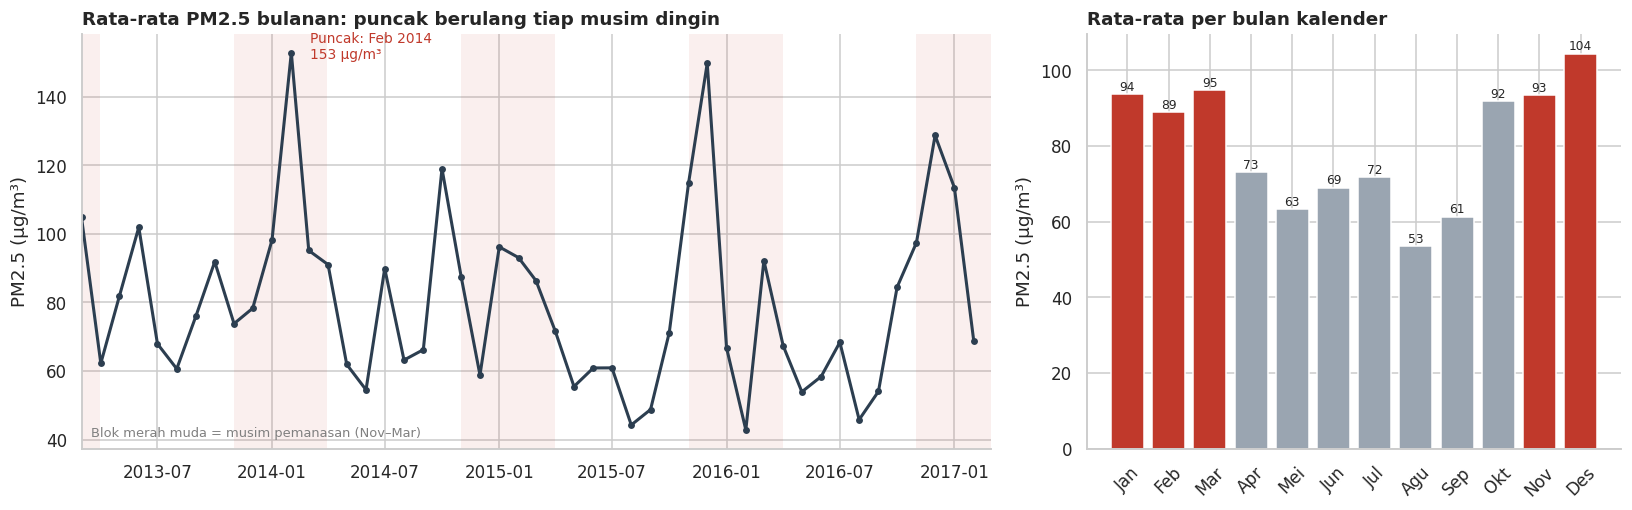

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={'width_ratios': [1.7, 1]})

# (a) Tren bulanan
ax = axes[0]
ax.plot(pm_bulanan['datetime'], pm_bulanan['pm25'], color=DARK, lw=2, marker='o', ms=3.5)
for y in range(2013, 2018):  # blok musim pemanasan (Nov-Mar)
    ax.axvspan(pd.Timestamp(f'{y-1}-11-01'), pd.Timestamp(f'{y}-03-31'), color=ACCENT, alpha=0.08, lw=0)
ax.set_xlim(pd.Timestamp('2013-03-01'), pd.Timestamp('2017-02-28'))
ax.set_title('Rata-rata PM2.5 bulanan: puncak berulang tiap musim dingin', loc='left', fontweight='bold')
ax.set_ylabel('PM2.5 (µg/m³)'); ax.set_xlabel('')
puncak = pm_bulanan.nlargest(1, 'pm25').iloc[0]
ax.annotate(f"Puncak: {puncak['datetime']:%b %Y}\n{puncak['pm25']:.0f} µg/m³",
            (puncak['datetime'], puncak['pm25']), xytext=(12, -4), textcoords='offset points', fontsize=9, color=ACCENT)
ax.text(0.01, 0.03, 'Blok merah muda = musim pemanasan (Nov–Mar)', transform=ax.transAxes, fontsize=8.5, color='gray')

# (b) Rata-rata per bulan kalender
ax = axes[1]
nama_bulan = ['Jan','Feb','Mar','Apr','Mei','Jun','Jul','Agu','Sep','Okt','Nov','Des']
warna = [ACCENT if m in (11, 12, 1, 2, 3) else BASE for m in pm_kalender.index]
ax.bar(nama_bulan, pm_kalender.values, color=warna)
ax.set_title('Rata-rata per bulan kalender', loc='left', fontweight='bold')
ax.set_ylabel('PM2.5 (µg/m³)')
ax.tick_params(axis='x', rotation=45)
for i, v in enumerate(pm_kalender.values):
    ax.text(i, v + 1, f'{v:.0f}', ha='center', fontsize=8)
plt.tight_layout(); plt.show()

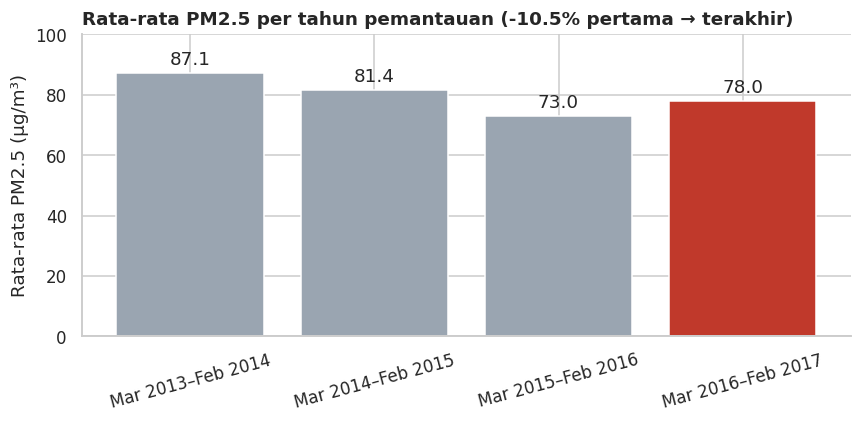

In [47]:
fig, ax = plt.subplots(figsize=(8, 4))
warna = [BASE, BASE, BASE, ACCENT]
bars = ax.bar(pm_periode.index.astype(str), pm_periode.values, color=warna)
ax.bar_label(bars, fmt='%.1f', padding=3)
ax.set_ylabel('Rata-rata PM2.5 (µg/m³)')
ax.set_title(f'Rata-rata PM2.5 per tahun pemantauan ({pm_periode.iloc[-1]/pm_periode.iloc[0]-1:+.1%} pertama → terakhir)', loc='left', fontweight='bold')
ax.set_ylim(0, pm_periode.max() * 1.15)
plt.xticks(rotation=15); plt.tight_layout(); plt.show()

### Pertanyaan 2: Stasiun mana yang tertinggi/terendah dan berapa persen jam tidak sehat?

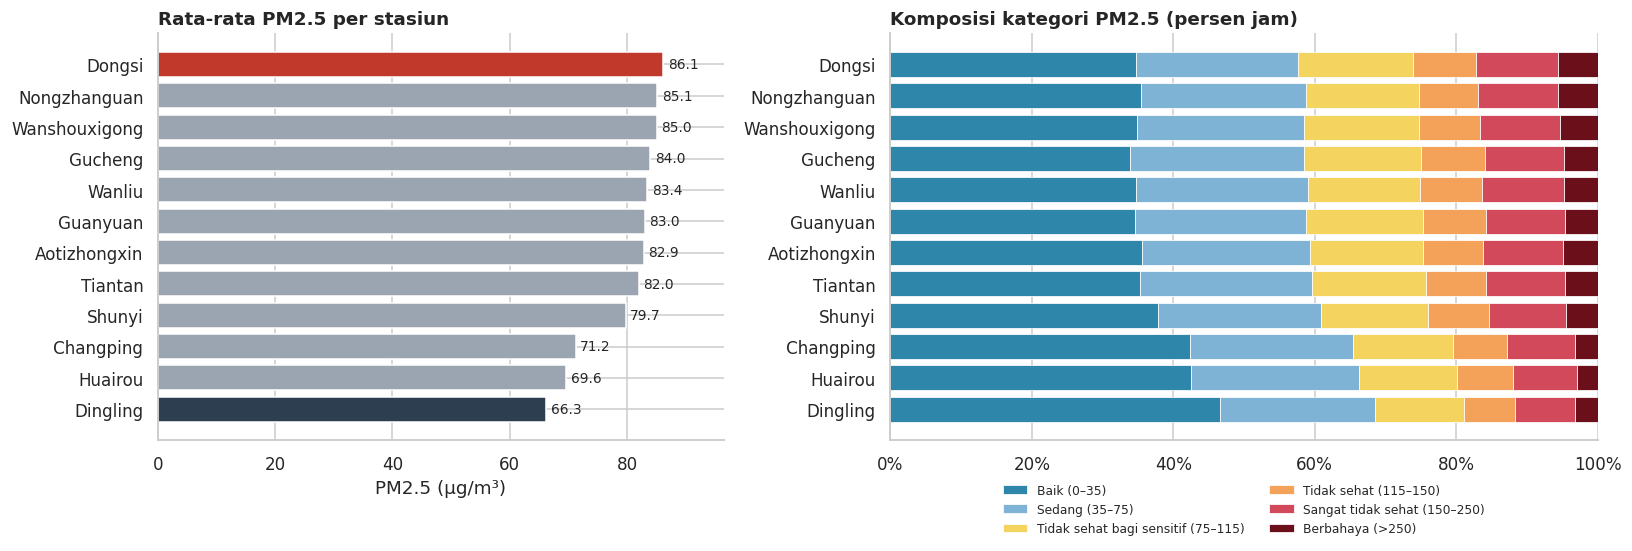

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={'width_ratios': [1, 1.25]})

# Rata-rata PM2.5 per stasiun
ax = axes[0]
st = stasiun.sort_values('rata2_pm25')
warna = [ACCENT if s == st.index[-1] else (DARK if s == st.index[0] else BASE) for s in st.index]
bars = ax.barh(st.index, st['rata2_pm25'], color=warna)
ax.bar_label(bars, fmt='%.1f', padding=3, fontsize=9)
ax.set_xlim(0, st['rata2_pm25'].max() * 1.12)
ax.set_title('Rata-rata PM2.5 per stasiun', loc='left', fontweight='bold')
ax.set_xlabel('PM2.5 (µg/m³)')

# Komposisi kategori (stacked 100%)
ax = axes[1]
kom = komposisi.loc[st.index]
palet = ['#2E86AB', '#7FB3D5', '#F4D35E', '#F4A259', '#D1495B', '#6B0F1A']
left = np.zeros(len(kom))
for col, c in zip(kom.columns, palet):
    ax.barh(kom.index, kom[col], left=left, color=c, label=col, edgecolor='white', lw=0.5)
    left += kom[col].values
ax.set_xlim(0, 100); ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title('Komposisi kategori PM2.5 (persen jam)', loc='left', fontweight='bold')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=2, fontsize=8, frameon=False)
plt.tight_layout(); plt.show()

### Pertanyaan 3: Jam puncak PM2.5 dan pengaruh kecepatan angin

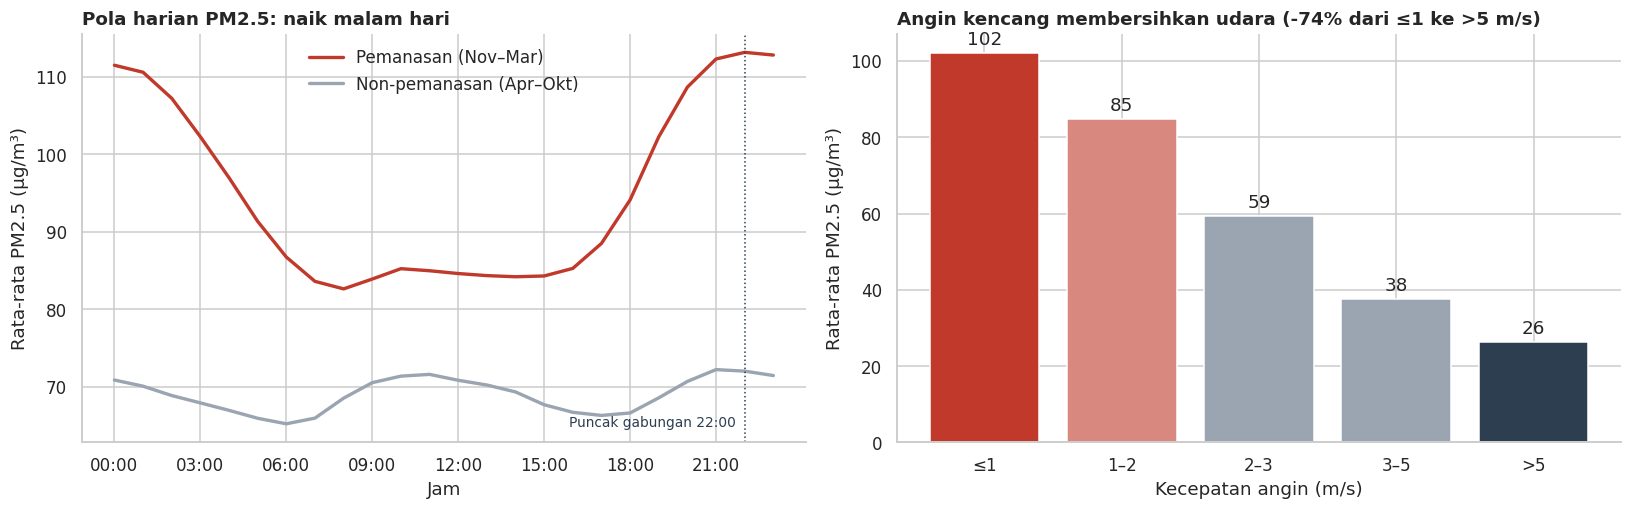

In [59]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

# Pola harian menurut musim
ax = axes[0]
pola = df_pm.groupby(['musim', 'hour'])['PM2.5'].mean().unstack(0)
ax.plot(pola.index, pola['Pemanasan (Nov–Mar)'], color=ACCENT, lw=2.2, label='Pemanasan (Nov–Mar)')
ax.plot(pola.index, pola['Non-pemanasan (Apr–Okt)'], color=BASE, lw=2.2, label='Non-pemanasan (Apr–Okt)')
ax.axvline(pm_jam.idxmax(), color=DARK, ls=':', lw=1)
ax.text(pm_jam.idxmax() - 0.3, ax.get_ylim()[0] + 2, f'Puncak gabungan {pm_jam.idxmax():02d}:00', ha='right', fontsize=9, color=DARK)
ax.set_xticks(range(0, 24, 3)); ax.set_xticklabels([f'{h:02d}:00' for h in range(0, 24, 3)])
ax.set_ylabel('Rata-rata PM2.5 (µg/m³)'); ax.set_xlabel('Jam')
ax.set_title('Pola harian PM2.5: naik malam hari', loc='left', fontweight='bold')
ax.legend(frameon=False)

# PM2.5 vs kecepatan angin
ax = axes[1]
warna = [ACCENT, '#D98880', BASE, BASE, DARK]
bars = ax.bar(pm_angin.index.astype(str), pm_angin['mean'], color=warna)
ax.bar_label(bars, fmt='%.0f', padding=3)
ax.set_xlabel('Kecepatan angin (m/s)'); ax.set_ylabel('Rata-rata PM2.5 (µg/m³)')
ax.set_title(f'Angin kencang membersihkan udara ({pm_angin["mean"].iloc[-1]/pm_angin["mean"].iloc[0]-1:+.0%} dari ≤1 ke >5 m/s)', loc='left', fontweight='bold')
plt.tight_layout(); plt.show()

**Insight:**
- **Pertanyaan 1:** polusi berulang memuncak tiap musim dingin dan terendah di musim panas (Agustus). Tren tahunan membaik pada 2013 → 2015 tetapi **berbalik naik** pada periode terakhir.
- **Pertanyaan 2:** pusat kota lebih tercemar dibanding pinggiran utara; sekitar seperempat jam pengukuran berada di atas 115 µg/m³ di hampir semua stasiun.
- **Pertanyaan 3:** puncak harian terjadi pada malam hari, dan angin kencang adalah faktor cuaca paling kuat yang menurunkan PM2.5.

## Analisis Lanjutan (Opsional)

Analisis lanjutan tanpa algoritma *machine learning*: **(1) Geospatial analysis** peta interaktif folium, **(2) Manual grouping** stasiun ke dalam tingkat risiko, dan **(3) analisis arah angin** untuk melihat kondisi pembawa polusi. Binning kategori PM2.5 sudah dilakukan pada tahap cleaning.

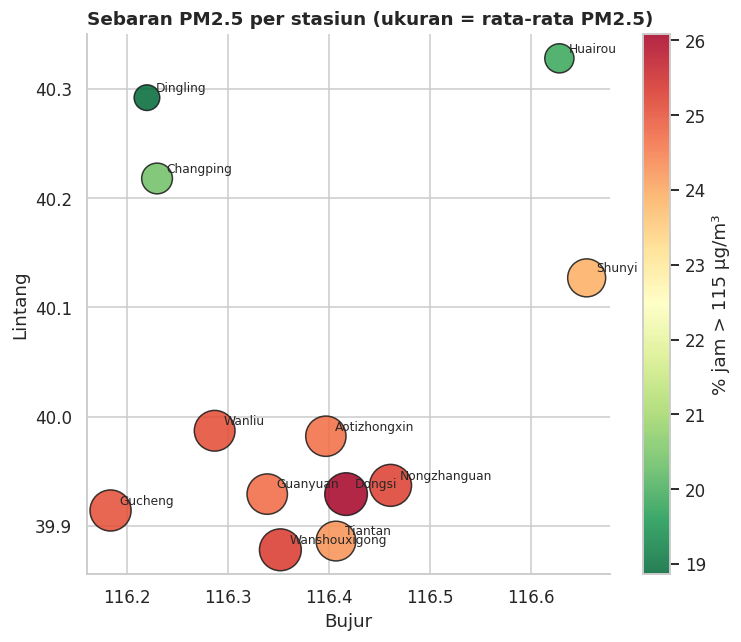

In [50]:
koordinat = {
    'Aotizhongxin': (39.982, 116.397), 'Changping': (40.218, 116.230), 'Dingling': (40.292, 116.220),
    'Dongsi': (39.929, 116.417), 'Guanyuan': (39.929, 116.339), 'Gucheng': (39.914, 116.184),
    'Huairou': (40.328, 116.628), 'Nongzhanguan': (39.937, 116.461), 'Shunyi': (40.127, 116.655),
    'Tiantan': (39.886, 116.407), 'Wanliu': (39.987, 116.287), 'Wanshouxigong': (39.878, 116.352),
}
geo = stasiun.copy()
geo['lat'] = [koordinat[s][0] for s in geo.index]
geo['lon'] = [koordinat[s][1] for s in geo.index]

# Manual grouping berdasarkan tingkat persentase jam > 115 µg/m³
geo['tingkat_risiko'] = pd.cut(geo['persen_jam_tidak_sehat'], bins=[0, 22, 25, 100],
                               labels=['Rendah (<22%)', 'Sedang (22–25%)', 'Tinggi (>25%)'])
warna_risiko = {'Rendah (<22%)': 'green', 'Sedang (22–25%)': 'orange', 'Tinggi (>25%)': 'red'}

peta = folium.Map(
    location=[40.05, 116.33], zoom_start=10,
    tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}',
    attr='Tiles © Esri'
)
for nama, r in geo.iterrows():
    folium.CircleMarker(
        location=[r['lat'], r['lon']], radius=(r['rata2_pm25'] - 55) / 2.2,
        color=warna_risiko[r['tingkat_risiko']], fill=True, fill_opacity=0.65,
        tooltip=(f"<b>{nama}</b><br>Rata-rata PM2.5: {r['rata2_pm25']:.1f} µg/m³"
                 f"<br>Jam > 115 µg/m³: {r['persen_jam_tidak_sehat']:.1f}%<br>Risiko: {r['tingkat_risiko']}")
    ).add_to(peta)
display(peta)

fig, ax = plt.subplots(figsize=(7, 6))
sc = ax.scatter(geo['lon'], geo['lat'], s=(geo['rata2_pm25'] - 55) * 25,
                c=geo['persen_jam_tidak_sehat'], cmap='RdYlGn_r', edgecolor='k', alpha=0.85)
for nama, r in geo.iterrows():
    ax.annotate(nama, (r['lon'], r['lat']), xytext=(6, 4), textcoords='offset points', fontsize=8)
plt.colorbar(sc, label='% jam > 115 µg/m³')
ax.set_xlabel('Bujur'); ax.set_ylabel('Lintang')
ax.set_title('Sebaran PM2.5 per stasiun (ukuran = rata-rata PM2.5)', loc='left', fontweight='bold')
plt.tight_layout(); plt.show()

In [51]:
geo[['rata2_pm25', 'persen_jam_tidak_sehat', 'tingkat_risiko']].sort_values('rata2_pm25', ascending=False)

,rata2_pm25,persen_jam_tidak_sehat,tingkat_risiko
station,,,
Dongsi,86.13,26.09,Tinggi (>25%)
Nongzhanguan,85.15,25.23,Tinggi (>25%)
Wanshouxigong,85.03,25.29,Tinggi (>25%)
Gucheng,83.96,25.03,Tinggi (>25%)
Wanliu,83.43,25.07,Tinggi (>25%)
Guanyuan,82.99,24.68,Sedang (22–25%)
Aotizhongxin,82.86,24.67,Sedang (22–25%)
Tiantan,82.04,24.25,Sedang (22–25%)
Shunyi,79.73,23.92,Sedang (22–25%)


{'ESE': 102.1, 'E': 101.7, 'ENE': 97.9, 'SE': 96.9}
{'NW': 51.6, 'NNW': 53.8, 'WNW': 56.8, 'N': 67.3}


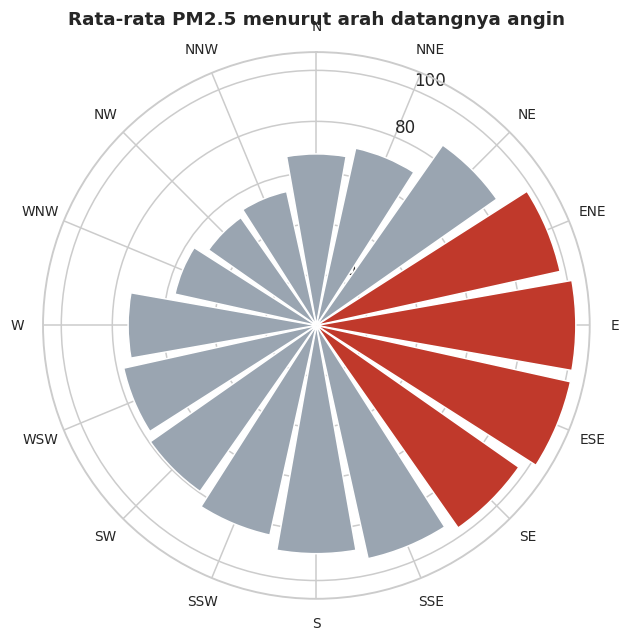

In [52]:
# Analisis arah angin (wd) yang membawa PM2.5 paling tinggi?
urutan_wd = ['N','NNE','NE','ENE','E','ESE','SE','SSE','S','SSW','SW','WSW','W','WNW','NW','NNW']
pm_wd = df_pm.groupby('wd')['PM2.5'].mean().reindex(urutan_wd)
print(pm_wd.sort_values(ascending=False).round(1).head(4).to_dict())
print(pm_wd.sort_values().round(1).head(4).to_dict())

fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(111, polar=True)
theta = np.deg2rad(np.arange(0, 360, 22.5))
ax.set_theta_zero_location('N'); ax.set_theta_direction(-1)
ax.bar(theta, pm_wd.values, width=np.deg2rad(20), color=[ACCENT if v > 95 else BASE for v in pm_wd.values])
ax.set_xticks(theta); ax.set_xticklabels(urutan_wd, fontsize=9)
ax.set_title('Rata-rata PM2.5 menurut arah datangnya angin', fontweight='bold', pad=18)
plt.tight_layout(); plt.show()

**Insight:**
- **Geospasial:** stasiun dengan risiko tinggi berkumpul di **pusat kota** (Dongsi, Nongzhanguan, Wanshouxigong, Gucheng, Wanliu); risiko rendah di **pinggiran utara** (Dingling, Huairou, Changping), yang lebih jauh dari lalu lintas dan aktivitas perkotaan padat.
- **Arah angin (Wind Direction):** angin dari **timur–tenggara (E, ESE, ENE, SE)** membawa PM2.5 tertinggi (±97–102 µg/m³), sedangkan angin dari **barat laut (NW, NNW, WNW)** paling bersih (±52–57 µg/m³). Ini konsisten dengan pola umum: udara dari barat laut lebih bersih dan kencang, sedangkan udara dari arah tenggara cenderung stagnan dan membawa polutan dari wilayah padat di selatan–timur. Ini asosiasi statistik, bukan bukti sebab-akibat.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** PM2.5 di Beijing sangat musiman: **Desember tertinggi (±104 µg/m³)** dan Agustus terendah (±53 µg/m³); musim pemanasan (Nov–Mar) rata-rata **±38% lebih tinggi** dibanding Apr–Okt. Rata-rata tahunan turun dari ±87 menjadi ±78 µg/m³ antara Mar 2013–Feb 2014 dan Mar 2016–Feb 2017 (**±−10,5%**), tetapi perbaikan tidak konsisten karena tahun terakhir justru naik dibanding periode Mar 2015–Feb 2016 (±73 µg/m³).

- **Conclusion pertanyaan 2:** **Dongsi** adalah stasiun paling tercemar (±86 µg/m³; ±26,1% jam > 115 µg/m³) dan **Dingling** paling bersih (±66 µg/m³; ±18,9%), selisih ±30%. Secara umum pusat kota lebih tercemar daripada pinggiran utara, dan hampir seperempat (±23,6%) jam
pengukuran berada di kategori tidak sehat atau lebih buruk.
- **Conclusion pertanyaan 3:** PM2.5 memuncak pada **malam hari (±21–23:00, ±89 µg/m³)**, ±22% lebih tinggi dari titik terendah (±07:00). Kecepatan angin adalah pembeda terkuat: PM2.5 turun **±74%** dari ±102 µg/m³ (angin ≤1 m/s) menjadi ±26 µg/m³ (angin >5 m/s).

**Rekomendasi Action Item:**
- **Jadwalkan intervensi musiman:** pusatkan pembatasan emisi (pemanas, industri, lalu lintas berat) dan kampanye masker **mulai Oktober hingga Maret**, dengan kesiapsiagaan tertinggi pada **Desember**.
- **Prioritaskan wilayah pusat kota:** alokasikan pengawasan dan intervensi lebih dulu ke **Dongsi, Nongzhanguan, Wanshouxigong, Gucheng, dan Wanliu**; pakai Dingling/Huairou sebagai pembanding *baseline*.
- **Peringatan dini berbasis jam dan cuaca:** kirim peringatan kesehatan sore hari (sebelum ±18:00) serta pemicu **status siaga** saat angin ≤1 m/s, terutama bila angin datang dari sektor timur–tenggara; saat angin kencang dari barat laut, peringatan dapat dilonggarkan.
- **Evaluasi kebijakan secara berkala:** karena tren menurun tidak stabil, tetapkan target penurunan tahunan dan pantau dengan indikator yang sama (rata-rata PM2.5 per tahun dan persentase jam > 115 µg/m³).
- **Keterbatasan:** data hanya sampai Februari 2017 dan koordinat stasiun diperkirakan, sehingga hasil perlu divalidasi dengan data terbaru.

## Ekspor Data

In [53]:
main_data = df_pm[['datetime', 'station', 'PM2.5', 'WSPM', 'wd']].copy()
main_data['PM2.5'] = main_data['PM2.5'].round(1)
main_data['WSPM'] = main_data['WSPM'].round(1)
main_data.to_csv('main_data.csv', index=False)
print('main_data:', main_data.shape)

(pd.DataFrame(koordinat, index=['lat', 'lon']).T
   .rename_axis('station').reset_index()
   .to_csv('station_locations.csv', index=False))

main_data: (417414, 5)
